# 01 - Data Preparation

Choose a dataset, downscale images to <= 64x64, and create the 70/15/15 train/validation/test split used by every other notebook.

**Dataset:** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) (Kaggle) - 6-class natural scene classification.

In [1]:
# --- Environment setup (Google Colab + shared Google Drive) ---
import os

try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Mount the team's shared Google Drive. We use it to persist the
    # resized/normalized dataset + split metadata across sessions, so we
    # don't have to re-download and re-preprocess ~17k images every time
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN"
    os.makedirs(DRIVE_ROOT, exist_ok=True)
else:
    # Local fallback (e.g. running outside Colab) - adjust as needed.
    DRIVE_ROOT = os.path.abspath("..")

# Packages not always preinstalled in the Colab base image.
!pip install -q kaggle

print("IN_COLAB:", IN_COLAB)
print("DRIVE_ROOT:", DRIVE_ROOT)


Mounted at /content/drive
IN_COLAB: True
DRIVE_ROOT: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN


## 1. Config

In [2]:
# --- Config for this notebook (defined here, not in a shared file) ---
CONFIG = {
    "image_size": 64,
    "channels": 3,
    "train_ratio": 0.70,
    "val_ratio": 0.15,
    "test_ratio": 0.15,
    "random_seed": 42,
    "batch_size": 32,
    "epochs": 20,               # requires >= 20 epochs
    "dataset_name": "Intel Image Classification",
    "kaggle_dataset": "puneet6060/intel-image-classification",
    "num_classes": 6,
    "class_names": ["buildings", "forest", "glacier", "mountain", "sea", "street"],
}

# --- Paths ---
# Raw JPEGs are kept on Colab's local disk (re-downloaded each session -
# cheap, ~350MB zip). Only the small/derived artifacts below are persisted
# to the shared Drive, so notebooks 02-08 never need to touch Kaggle at all.
RAW_DATA_DIR = os.path.join(DRIVE_ROOT, "data", "raw", "intel-image-classification")
PROCESSED_DIR = os.path.join(DRIVE_ROOT, "data", "processed", "intel-image-classification")
SPLITS_DIR_DRIVE = os.path.join(DRIVE_ROOT, "data", "splits")

# Optional: point this at the repo's local path (e.g. if you've git-cloned
# it onto Drive) to also mirror the small split-metadata CSV there, next to
# data/splits/.gitkeep. Leave as None to skip - the CSV still lives on Drive.
REPO_ROOT = None  # e.g. "/content/drive/MyDrive/EN3150_A03_Shared/EN3150-A03-Resource-Constrained-CNN"
SPLITS_DIR_REPO = os.path.join(REPO_ROOT, "data", "splits") if REPO_ROOT else None

for d in (RAW_DATA_DIR, PROCESSED_DIR, SPLITS_DIR_DRIVE):
    os.makedirs(d, exist_ok=True)

CONFIG


{'image_size': 64,
 'channels': 3,
 'train_ratio': 0.7,
 'val_ratio': 0.15,
 'test_ratio': 0.15,
 'random_seed': 42,
 'batch_size': 32,
 'epochs': 20,
 'dataset_name': 'Intel Image Classification',
 'kaggle_dataset': 'puneet6060/intel-image-classification',
 'num_classes': 6,
 'class_names': ['buildings',
  'forest',
  'glacier',
  'mountain',
  'sea',
  'street']}

## 2. Imports

In [3]:
import glob
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Seed

In [5]:
SEED = CONFIG["random_seed"]
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 4. Dataset Selection

**Dataset: Intel Image Classification** ([Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification): `puneet6060/intel-image-classification`, originally released by Intel for an Analytics Vidhya image-classification challenge).

- **Classes (6):** buildings, forest, glacier, mountain, sea, street
- **Images used:** ~17,034 labeled photos - Kaggle's `seg_train` (14,034) + `seg_test` (3,000) folders, combined and re-split ourselves (see Section 9). The `seg_pred` folder (~7,301 images) is unlabeled and is **not** used.
- **Original resolution:** 150x150 RGB JPEG.
- **Why this dataset:** 6-way natural-scene classification is a realistic edge/mobile vision workload (e.g. on-device scene tagging). Images are small to begin with, so downscaling to <=64x64 is reasonable, and classes are visually distinct but have real confusable pairs (glacier vs. mountain, sea vs. glacier), giving Model A/B and the SOTA fine-tunes a non-trivial problem.
- We combine Kaggle's own `seg_train` + `seg_test` splits and draw our **own** stratified 70/15/15 split (Section 9) rather than reusing Kaggle's split, so the assignment's split requirement is met exactly.


The raw dataset is fetched fresh from Kaggle each Colab session (Section 5) and is **not** committed to GitHub or downloaded to individual PCs; the resized/normalized arrays produced below are cached on the shared Google Drive (`PROCESSED_DIR`).

## 5. Load Raw Dataset

In [ ]:
if IN_COLAB:
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
else:
    # Local fallback: expects ~/.kaggle/kaggle.json to already exist.
    pass

assert os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"), (
    "Kaggle credentials not found - add KAGGLE_USERNAME/KAGGLE_KEY as Colab "
    "secrets (key icon in the left sidebar) and enable notebook access."
)
print("Kaggle credentials loaded for user:", os.environ["KAGGLE_USERNAME"])


Kaggle credentials loaded for user: CNN


In [ ]:
# --- Download + unzip the dataset (skips re-download if already cached) ---
_marker = os.path.join(RAW_DATA_DIR, ".downloaded")
if not os.path.exists(_marker):
    !kaggle datasets download -d {CONFIG["kaggle_dataset"]} -p {RAW_DATA_DIR} --unzip
    open(_marker, "w").close()
else:
    print("Already downloaded, skipping:", RAW_DATA_DIR)

!find {RAW_DATA_DIR} -maxdepth 3 -type d | sort


Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:04<00:00, 84.9MB/s]

/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/raw/intel-image-classification
/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/raw/intel-image-classification/seg_pred
/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/raw/intel-image-classification/seg_pred/seg_pred
/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/raw/intel-image-classification/seg_test
/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/raw/intel-image-classification/seg_test/seg_test
/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/raw/intel-image-classification/seg_tes

In [ ]:
# Intel Image Classification unzips to seg_train/seg_train/<class>/*.jpg and
# seg_test/seg_test/<class>/*.jpg (seg_pred/seg_pred/*.jpg is unlabeled ->
# skipped). Kaggle occasionally changes the nesting depth, so search for it.
def find_split_dir(root, split_name):
    matches = glob.glob(os.path.join(root, "**", split_name), recursive=True)
    # Prefer the deepest match containing class subfolders.
    matches = [m for m in matches if os.path.isdir(m)]
    return matches[-1] if matches else os.path.join(root, split_name)

train_dir = find_split_dir(RAW_DATA_DIR, "seg_train")
test_dir = find_split_dir(RAW_DATA_DIR, "seg_test")
print("train_dir:", train_dir)
print("test_dir:", test_dir)

records = []
for split_dir in (train_dir, test_dir):
    for class_name in CONFIG["class_names"]:
        class_dir = os.path.join(split_dir, class_name)
        for fp in glob.glob(os.path.join(class_dir, "*.jpg")):
            records.append({"filepath": fp, "label": class_name})

raw_df = pd.DataFrame(records)
print(f"Found {len(raw_df)} labeled images across {raw_df['label'].nunique()} classes")
raw_df.head()


train_dir: /content/data/raw/intel-image-classification/seg_train/seg_train
test_dir: /content/data/raw/intel-image-classification/seg_test/seg_test
Found 17034 labeled images across 6 classes


,filepath,label
0,/content/data/raw/intel-image-classification/s...,buildings
1,/content/data/raw/intel-image-classification/s...,buildings
2,/content/data/raw/intel-image-classification/s...,buildings
3,/content/data/raw/intel-image-classification/s...,buildings
4,/content/data/raw/intel-image-classification/s...,buildings


## 6. Explore Dataset (EDA)

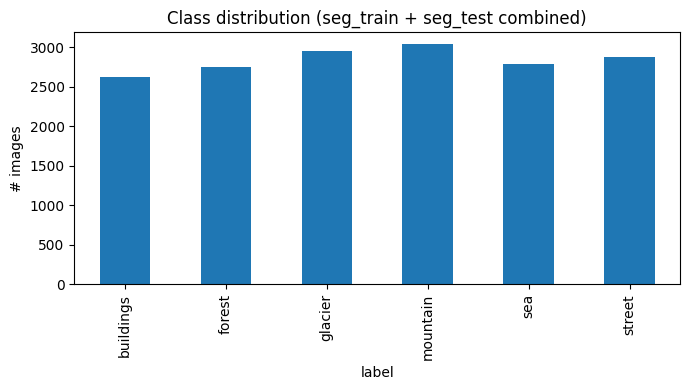

label
buildings    2628
forest       2745
glacier      2957
mountain     3037
sea          2784
street       2883
Name: count, dtype: int64


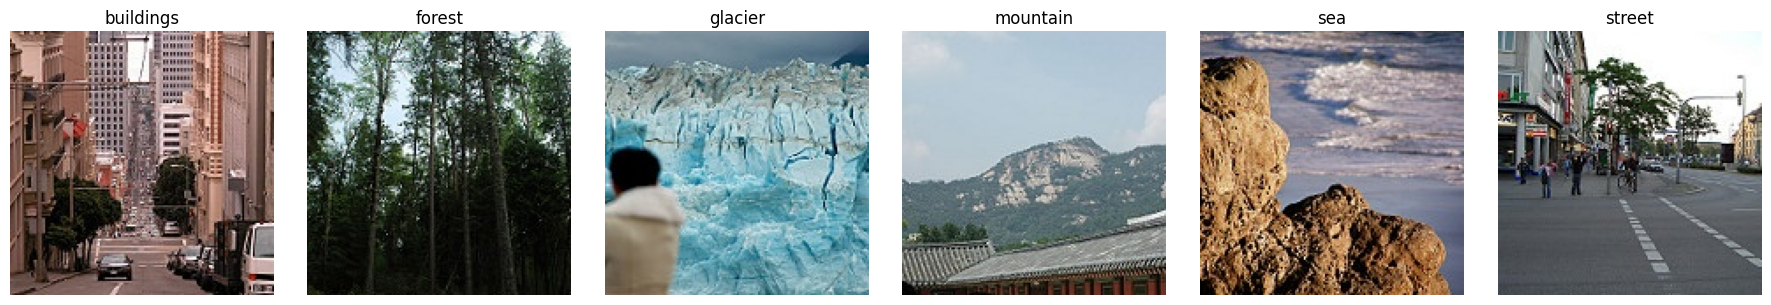

Checked 2000 images -> 0 corrupt/unreadable
Most common original resolution(s):
(150, 150)    1990
(150, 135)       2
(150, 136)       1
(150, 108)       1
(150, 72)        1
Name: count, dtype: int64


In [ ]:
# --- Class distribution ---
class_counts = raw_df["label"].value_counts().reindex(CONFIG["class_names"])
ax = class_counts.plot(kind="bar", figsize=(7, 4), title="Class distribution (seg_train + seg_test combined)")
ax.set_ylabel("# images")
plt.tight_layout()
plt.show()
print(class_counts)

# --- Sample image per class ---
fig, axes = plt.subplots(1, CONFIG["num_classes"], figsize=(3 * CONFIG["num_classes"], 3))
for ax, class_name in zip(axes, CONFIG["class_names"]):
    sample_fp = raw_df.loc[raw_df["label"] == class_name, "filepath"].iloc[0]
    ax.imshow(Image.open(sample_fp))
    ax.set_title(class_name)
    ax.axis("off")
plt.tight_layout()
plt.show()

# --- Corrupt-file check + original resolution survey (subsample for speed;
#     the resize step in Section 7 does a full, exhaustive pass and drops
#     anything unreadable) ---
sample_df = raw_df.sample(n=min(2000, len(raw_df)), random_state=SEED)
sizes, corrupt = [], []
for fp in sample_df["filepath"]:
    try:
        with Image.open(fp) as img:
            img.verify()
        with Image.open(fp) as img:
            sizes.append(img.size)
    except Exception:
        corrupt.append(fp)

print(f"Checked {len(sample_df)} images -> {len(corrupt)} corrupt/unreadable")
print("Most common original resolution(s):")
print(pd.Series(sizes).value_counts().head())


## 7. Resize to <= 64x64

In [ ]:
def load_and_resize(filepath, size=CONFIG["image_size"]):
    img = Image.open(filepath).convert("RGB").resize((size, size), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

t0 = time.time()
images_list, kept_mask = [], []
for fp in raw_df["filepath"]:
    try:
        images_list.append(load_and_resize(fp))
        kept_mask.append(True)
    except Exception as e:
        print("Skipping unreadable file:", fp, "-", e)
        kept_mask.append(False)

kept_mask = np.array(kept_mask)
if not kept_mask.all():
    print(f"Dropped {(~kept_mask).sum()} unreadable/corrupt image(s)")

raw_df = raw_df.loc[kept_mask].reset_index(drop=True)
images = np.stack(images_list)
labels = raw_df["label"].to_numpy()

print(f"Resized {len(images)} images to {images.shape[1:]} in {time.time() - t0:.1f}s")
print("images dtype/shape:", images.dtype, images.shape)


Resized 17034 images to (64, 64, 3) in 16.7s
images dtype/shape: uint8 (17034, 64, 64, 3)


## 8. Normalize

In [ ]:
# Scale pixel values from [0, 255] uint8 to [0, 1] float32. We store this
# normalized version (rather than re-normalizing on the fly in every later
# notebook) so notebooks 02-08 can just load ready-to-train arrays.
images_normalized = images.astype("float32") / 255.0
print("min/max after normalization:", images_normalized.min(), images_normalized.max())

label_to_index = {name: i for i, name in enumerate(CONFIG["class_names"])}
label_indices = np.array([label_to_index[l] for l in labels], dtype=np.int64)


min/max after normalization: 0.0 1.0


## 9. Train / Validation / Test Split (70/15/15)

In [ ]:
# Stratified 70/15/15 split: first carve off (val + test) = 30%, then split
# that remainder evenly into 15%/15%. `idx_*` are positional indices into
# raw_df / images_normalized / label_indices, kept so we can record each
# image's original filepath + split assignment in the metadata CSV below.
all_idx = np.arange(len(images_normalized))

X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    images_normalized,
    label_indices,
    all_idx,
    test_size=(CONFIG["val_ratio"] + CONFIG["test_ratio"]),
    stratify=label_indices,
    random_state=CONFIG["random_seed"],
)

relative_test_size = CONFIG["test_ratio"] / (CONFIG["val_ratio"] + CONFIG["test_ratio"])
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp,
    y_temp,
    idx_temp,
    test_size=relative_test_size,
    stratify=y_temp,
    random_state=CONFIG["random_seed"],
)

n_total = len(images_normalized)
print("train/val/test sizes:", len(X_train), len(X_val), len(X_test))
print(
    "ratios:",
    round(len(X_train) / n_total, 3),
    round(len(X_val) / n_total, 3),
    round(len(X_test) / n_total, 3),
)


train/val/test sizes: 11923 2555 2556
ratios: 0.7 0.15 0.15


## 10. Save Split Metadata

We persist two things, to two different places (see [Data & model policy](../README.md#data--model-policy)):

- The actual preprocessed image arrays (`X_*.npy` / `y_*.npy`, large) -> **shared Google Drive only** (`PROCESSED_DIR`), never this repo.
- Lightweight split *metadata* - each image's original filepath, label, and split assignment as one CSV -> Drive, and optionally mirrored into this repo's `data/splits/` (small, and gitignored anyway, but handy to inspect locally).

In [ ]:
# --- Large arrays: shared Drive only ---
np.save(os.path.join(PROCESSED_DIR, "X_train.npy"), X_train)
np.save(os.path.join(PROCESSED_DIR, "y_train.npy"), y_train)
np.save(os.path.join(PROCESSED_DIR, "X_val.npy"), X_val)
np.save(os.path.join(PROCESSED_DIR, "y_val.npy"), y_val)
np.save(os.path.join(PROCESSED_DIR, "X_test.npy"), X_test)
np.save(os.path.join(PROCESSED_DIR, "y_test.npy"), y_test)

with open(os.path.join(PROCESSED_DIR, "class_names.json"), "w") as f:
    json.dump(CONFIG["class_names"], f)

# --- Small split-metadata CSV: Drive, and optionally the repo ---
meta_df = raw_df.copy()
meta_df["label_index"] = meta_df["label"].map(label_to_index)
meta_df["split"] = "train"
meta_df.loc[meta_df.index.isin(idx_val), "split"] = "val"
meta_df.loc[meta_df.index.isin(idx_test), "split"] = "test"

save_dirs = [SPLITS_DIR_DRIVE] + ([SPLITS_DIR_REPO] if SPLITS_DIR_REPO else [])
for out_dir in save_dirs:
    os.makedirs(out_dir, exist_ok=True)
    meta_df.to_csv(os.path.join(out_dir, "intel_image_classification_splits.csv"), index=False)

print("Saved processed arrays + class_names.json to:", PROCESSED_DIR)
print("Saved split metadata CSV to:", *save_dirs)


Saved processed arrays + class_names.json to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/processed/intel-image-classification
Saved split metadata CSV to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/EN3150-A03-Resource-Constrained-CNN/data/splits


## 11. Sanity Checks

In [ ]:
# Reload from disk (simulates what notebooks 02-08 will actually do) and verify.
X_train_chk = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train_chk = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))

expected_shape = (CONFIG["image_size"], CONFIG["image_size"], CONFIG["channels"])
assert X_train_chk.shape[1:] == expected_shape, X_train_chk.shape
assert X_train_chk.dtype == np.float32, X_train_chk.dtype
assert 0.0 <= X_train_chk.min() and X_train_chk.max() <= 1.0
assert set(np.unique(y_train_chk)) <= set(range(CONFIG["num_classes"]))

n_total = len(X_train) + len(X_val) + len(X_test)
print(
    f"train={len(X_train)} ({len(X_train) / n_total:.1%})  "
    f"val={len(X_val)} ({len(X_val) / n_total:.1%})  "
    f"test={len(X_test)} ({len(X_test) / n_total:.1%})"
)

for name, y in (("train", y_train), ("val", y_val), ("test", y_test)):
    dist = pd.Series(y).value_counts(normalize=True).sort_index()
    dist_named = {CONFIG["class_names"][i]: round(float(v), 3) for i, v in dist.items()}
    print(f"{name} class balance:", dist_named)

print("All sanity checks passed.")


train=11923 (70.0%)  val=2555 (15.0%)  test=2556 (15.0%)
train class balance: {'buildings': 0.154, 'forest': 0.161, 'glacier': 0.174, 'mountain': 0.178, 'sea': 0.163, 'street': 0.169}
val class balance: {'buildings': 0.155, 'forest': 0.161, 'glacier': 0.173, 'mountain': 0.178, 'sea': 0.164, 'street': 0.169}
test class balance: {'buildings': 0.154, 'forest': 0.161, 'glacier': 0.174, 'mountain': 0.178, 'sea': 0.163, 'street': 0.169}
All sanity checks passed.


## 12. Conclusion

We chose the **Intel Image Classification** dataset (6 natural-scene classes: buildings, forest, glacier, mountain, sea, street) - ~17k labeled images after combining Kaggle's `seg_train` + `seg_test`. All images were downscaled to 64x64x3, pixel values normalized to [0, 1], and split 70/15/15 (stratified by class, `random_seed=42`) - see Section 11 for the exact counts and per-class balance.

The resized/normalized arrays (`X_{train,val,test}.npy`, `y_{train,val,test}.npy`) and `class_names.json` are cached on the shared Google Drive under `data/processed/intel-image-classification/`; a CSV recording each image's original filepath, label, and split assignment is saved under `data/splits/`. **Notebooks 02-08 should load directly from `PROCESSED_DIR`** (mount Drive, then `np.load(...)`) rather than re-downloading or re-processing from Kaggle.

Caveat: we deliberately re-split Kaggle's own `seg_train` + `seg_test` images ourselves to get an honest, class-stratified 70/15/15 split as required by the assignment, rather than reusing Kaggle's original train/test split. The unlabeled `seg_pred` folder was not used.